# URN4-M SVM Experiment: Boston Tracts (cul_de_sac vs gridiron vs organic vs hybrid)

This notebook replicates the city-replication SVM pipeline at tract level in Boston using four specific tracts from `data/urban_patterns_clustered.geojson`:
- 1st row -> cul_de_sac (feature index 0)
- 2nd row -> gridiron (feature index 1)
- 5th row -> organic (feature index 4, original label `organico`)
- 10th row -> hybrid (feature index 9, original label `hibrido`)

Parameters:
- Subgraphs per class: 800
- Local subgraph sampling: configurable (`radius` or `n_nearest_nodes`)
- Network type: drive


In [2]:
import sys
from pathlib import Path
def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "graph_kernels").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
GRAPH_KERNELS_ROOT = REPO_ROOT / "graph_kernels"
if str(GRAPH_KERNELS_ROOT) not in sys.path:
    sys.path.append(str(GRAPH_KERNELS_ROOT))
NOTEBOOK_DIR = GRAPH_KERNELS_ROOT / "boston_example"

from src.graph_utils import compute_Q, kttw
from src.graph_dataset_preparation import ensure_unique_edge_weights


In [3]:
import geopandas as gpd
import osmnx as ox
import networkx as nx
import numpy as np
from tqdm import tqdm

SEED = 50
SUBGRAPHS_PER_CLASS = 10
SAMPLING_MODE = "n_nearest"  # Choose: "radius" or "n_nearest"
R_LOCAL = 400
N_LOCAL_NODES = 15
NETWORK_TYPE = "drive"
MAX_ATTEMPTS_FACTOR = 80
GEOJSON_PATH = NOTEBOOK_DIR / "data" / "urban_patterns_clustered.geojson"
AUTO_BALANCED_TRACTS_PER_CLASS = 30

# Option A: manual tract selection for quick testing.
TRACT_SPECS = [
    {"feature_index": 0},
    {"feature_index": 1},
    {"feature_index": 2},
    {"feature_index": 3},

]

PATTERN_TO_CLASS_NAME = {
    "cul_de_sac": "cul_de_sac",
    "gridiron": "gridiron",
    "organico": "organic",
    "hibrido": "hybrid",
}


def build_balanced_tract_specs_from_geojson(
    geojson_path,
    pattern_to_class_name,
    n_per_pattern,
    seed,
):
    if not isinstance(n_per_pattern, int) or n_per_pattern <= 0:
        raise ValueError("n_per_pattern must be a positive integer.")

    gdf = gpd.read_file(geojson_path)
    if "original_pattern" not in gdf.columns:
        raise ValueError("GeoJSON does not contain an 'original_pattern' column.")

    pattern_indices = {pattern: [] for pattern in pattern_to_class_name.keys()}
    for idx, pattern in enumerate(gdf["original_pattern"].tolist()):
        if pattern in pattern_indices:
            pattern_indices[pattern].append(idx)

    rng = np.random.default_rng(seed)
    tract_specs = []

    for pattern, class_name in pattern_to_class_name.items():
        available = pattern_indices[pattern]
        if len(available) < n_per_pattern:
            raise ValueError(
                f"Not enough tracts for pattern '{pattern}': "
                f"requested {n_per_pattern}, available {len(available)}."
            )

        selected = rng.choice(available, size=n_per_pattern, replace=False).tolist()
        for feature_index in selected:
            tract_specs.append(
                {
                    "feature_index": int(feature_index),
                    "expected_original_pattern": pattern,
                    "class_name": class_name,
                }
            )

    rng.shuffle(tract_specs)
    availability = {pattern: len(indices) for pattern, indices in pattern_indices.items()}
    return tract_specs, availability


# Option B: balanced automatic selection from GeoJSON.
# Set an integer (for example, 10) to sample that many tracts per pattern.
# Keep as None to use the manual TRACT_SPECS above.
if AUTO_BALANCED_TRACTS_PER_CLASS is not None:
    TRACT_SPECS, available_per_pattern = build_balanced_tract_specs_from_geojson(
        GEOJSON_PATH,
        PATTERN_TO_CLASS_NAME,
        n_per_pattern=AUTO_BALANCED_TRACTS_PER_CLASS,
        seed=SEED,
    )
    print(
        f"Auto-balanced TRACT_SPECS enabled: "
        f"{AUTO_BALANCED_TRACTS_PER_CLASS} tracts x {len(PATTERN_TO_CLASS_NAME)} classes "
        f"= {len(TRACT_SPECS)} total tracts."
    )
    print("Available tracts per original_pattern:", available_per_pattern)

np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
ox.settings.use_cache = True
ox.settings.log_console = False



Auto-balanced TRACT_SPECS enabled: 30 tracts x 4 classes = 120 total tracts.
Available tracts per original_pattern: {'cul_de_sac': 85, 'gridiron': 156, 'organico': 65, 'hibrido': 50}


In [4]:
def load_selected_tract_graphs(
    geojson_path,
    tract_specs,
    pattern_to_class_name,
    network_type="drive",
):
    gdf = gpd.read_file(geojson_path)

    if gdf.crs is None:
        gdf = gdf.set_crs(epsg=4326)
    elif gdf.crs.to_epsg() != 4326:
        gdf = gdf.to_crs(epsg=4326)

    graphs_by_feature_index = {}

    for spec in tract_specs:
        idx = spec["feature_index"]
        expected_pattern = spec.get("expected_original_pattern")

        if idx < 0 or idx >= len(gdf):
            raise IndexError(
                f"Feature index {idx} out of range for GeoJSON with {len(gdf)} rows."
            )

        row = gdf.iloc[idx]
        geom = row.geometry
        pattern = row.get("original_pattern", None)

        if expected_pattern is None:
            expected_pattern = pattern
        elif pattern != expected_pattern:
            print(
                f"Warning: index {idx} expected original_pattern='{expected_pattern}', "
                f"found '{pattern}'."
            )

        class_name = spec.get("class_name")
        if class_name is None:
            class_name = pattern_to_class_name.get(pattern, pattern)

        spec["class_name"] = class_name
        spec["expected_original_pattern"] = expected_pattern

        if geom is None or geom.is_empty:
            raise ValueError(f"Feature index {idx} has empty geometry.")
        if geom.geom_type not in {"Polygon", "MultiPolygon"}:
            raise ValueError(
                f"Feature index {idx} has unsupported geometry type: {geom.geom_type}."
            )

        print(
            f"Downloading tract graph for class='{class_name}' from feature index {idx} "
            f"(original_pattern='{pattern}')..."
        )

        G = ox.graph_from_polygon(
            geom,
            network_type=network_type,
            simplify=True,
        )
        G = ox.convert.to_undirected(G)

        G.graph["feature_index"] = idx
        G.graph["class_name"] = class_name
        G.graph["original_pattern"] = pattern

        print(f"  nodes={G.number_of_nodes()}, edges={G.number_of_edges()}")

        graphs_by_feature_index[idx] = G

    return graphs_by_feature_index


In [5]:
try:
    from utils.subgraph_sampling import (
        describe_sampling_config,
        sample_cycle_subgraphs_for_class,
    )
except ModuleNotFoundError:
    from boston_example.utils.subgraph_sampling import (
        describe_sampling_config,
        sample_cycle_subgraphs_for_class,
    )


In [6]:
tract_graphs = load_selected_tract_graphs(
    GEOJSON_PATH,
    TRACT_SPECS,
    pattern_to_class_name=PATTERN_TO_CLASS_NAME,
    network_type=NETWORK_TYPE,
)

graphs = []
labels = []

sampling_description = describe_sampling_config(
    SAMPLING_MODE,
    radius=R_LOCAL,
    n_nearest_nodes=N_LOCAL_NODES,
)

for spec in TRACT_SPECS:
    idx = spec["feature_index"]
    class_name = spec["class_name"]
    G_large = tract_graphs[idx]

    print(
        f"Sampling {SUBGRAPHS_PER_CLASS} cycle-containing subgraphs for {class_name} "
        f"({sampling_description})..."
    )
    class_graphs = sample_cycle_subgraphs_for_class(
        G_large,
        class_name=class_name,
        n_samples=SUBGRAPHS_PER_CLASS,
        sampling_mode=SAMPLING_MODE,
        radius=R_LOCAL,
        n_nearest_nodes=N_LOCAL_NODES,
        max_attempts_factor=MAX_ATTEMPTS_FACTOR,
        rng=RNG,
    )

    graphs.extend(class_graphs)
    labels.extend([class_name] * len(class_graphs))

print("Dataset generated.")
print(f"Total graphs: {len(graphs)}")
label_counts = {
    spec["class_name"]: int(np.sum(np.array(labels) == spec["class_name"]))
    for spec in TRACT_SPECS
}
print("Graphs per class:", label_counts)


  nodes=21, edges=24
  nodes=67, edges=85
  nodes=55, edges=68
  nodes=28, edges=41
  nodes=191, edges=266
  nodes=123, edges=165
  nodes=69, edges=91
  nodes=35, edges=40
  nodes=114, edges=141
  nodes=67, edges=85
  nodes=122, edges=176
  nodes=61, edges=72
  nodes=86, edges=111
  nodes=104, edges=134
  nodes=39, edges=45
  nodes=67, edges=88
  nodes=48, edges=63
  nodes=56, edges=73
  nodes=73, edges=91
  nodes=68, edges=94
  nodes=80, edges=98
  nodes=60, edges=67
  nodes=67, edges=88
  nodes=60, edges=75
  nodes=77, edges=100
  nodes=34, edges=46
  nodes=55, edges=66
  nodes=34, edges=40
  nodes=33, edges=40
  nodes=11, edges=11
  nodes=115, edges=148
  nodes=30, edges=37
  nodes=47, edges=56
  nodes=39, edges=40
  nodes=67, edges=96
  nodes=28, edges=31
  nodes=27, edges=33
  nodes=187, edges=243
  nodes=30, edges=43
  nodes=67, edges=93
  nodes=93, edges=120
  nodes=38, edges=49
  nodes=94, edges=120
  nodes=91, edges=124
  nodes=267, edges=347
  nodes=15, edges=19
  nodes=19, e

Accepted 10 graphs for 'organic' after 10 attempts.
Sampling 10 cycle-containing subgraphs for cul_de_sac (n_nearest_nodes=15)...


Accepted 10 graphs for 'cul_de_sac' after 10 attempts.
Sampling 10 cycle-containing subgraphs for hybrid (n_nearest_nodes=15)...


Accepted 10 graphs for 'hybrid' after 19 attempts.
Sampling 10 cycle-containing subgraphs for organic (n_nearest_nodes=15)...


Accepted 10 graphs for 'organic' after 10 attempts.
Sampling 10 cycle-containing subgraphs for cul_de_sac (n_nearest_nodes=15)...


Accepted 10 graphs for 'cul_de_sac' after 10 attempts.
Sampling 10 cycle-containing subgraphs for hybrid (n_nearest_nodes=15)...


... (111 outputs left out)

Accepted 10 graphs for 'hybrid' after 11 attempts.
Sampling 10 cycle-containing subgraphs for cul_de_sac (n_nearest_nodes=15)...


Accepted 10 graphs for 'cul_de_sac' after 10 attempts.
Sampling 10 cycle-containing subgraphs for cul_de_sac (n_nearest_nodes=15)...


Accepted 10 graphs for 'cul_de_sac' after 10 attempts.
Sampling 10 cycle-containing subgraphs for organic (n_nearest_nodes=15)...


Dataset generated.
Total graphs: 1190
Graphs per class: {'organic': 290, 'cul_de_sac': 300, 'hybrid': 300, 'gridiron': 300}


In [7]:
for i in range(len(graphs)):
    graphs[i] = graphs[i].to_undirected()

for G in graphs:
    if G.is_multigraph():
        for _, _, key, data in G.edges(keys=True, data=True):
            data["weight"] = float(data.get("length", 1.0))
    else:
        for _, _, data in G.edges(data=True):
            data["weight"] = float(data.get("length", 1.0))

graphs = ensure_unique_edge_weights(graphs)


In [8]:
for u, v, data in graphs[4].edges(data=True):
    print(u, v, data["weight"])

61343446 61343624 90.5459358209366
61343446 61344357 182.3761772594125
61343551 61392165 50.54536609154374
61343551 61343557 49.99452157121887
61343551 1171379907 86.08353845766094
61343624 61484874 33.36287767311736
61344357 13452149980 2.3702607929304014
61344357 13452127441 89.22442760315542
61344360 13452127441 1.6654671993268673
61344360 61484874 146.28365924182222
61344360 61392165 39.121527033397875
61516778 13452075506 28.432610725182133
61516778 13452149980 91.02944888264182
6016535227 6016535242 31.599367835259365
6016535242 13452075506 48.64268481377132


In [9]:
no_hole_indices = [i for i, G in enumerate(graphs) if nx.is_forest(G)]
print("Graphs without holes (acyclic):", len(no_hole_indices))
print("Total graphs:", len(graphs))


Graphs without holes (acyclic): 0
Total graphs: 1190


(<Figure size 800x800 with 1 Axes>, <Axes: >)

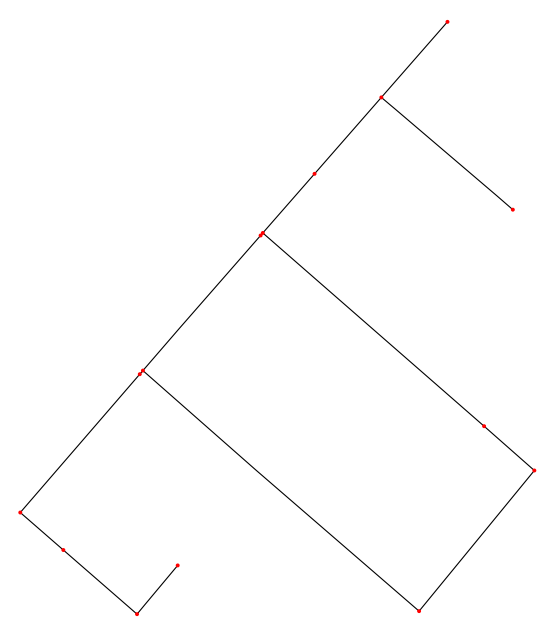

In [10]:
ox.plot_graph(
    graphs[7],
    node_size=8,
    node_color="red",
    edge_linewidth=0.8,
    edge_color="black",
    bgcolor="white",
    show=False,
    close=False,
)


In [ ]:
def normalize_edge_weights(G, weight_attr="weight"):
    # Get maximum weight
    max_weight = max(
        data.get(weight_attr, 1)
        for _, _, data in G.edges(data=True)
    )
    
    # Avoid division by zero
    if max_weight == 0:
        return G

    # Normalize weights
    for u, v, data in G.edges(data=True):
        data[weight_attr] = data.get(weight_attr, 1) / max_weight

    return G

#for i in range(0,len(graphs)):
#   graphs[i] = normalize_edge_weights(graphs[i])

In [12]:
Q_matrices = [compute_Q(G, alpha=0) for G in tqdm(graphs, desc="Computing Q")]

n_graphs = len(graphs)
gamma = 1
kts = np.zeros((n_graphs, n_graphs), dtype=float)

for i in tqdm(range(n_graphs), desc="Building kernel matrix"):
    kts[i, i] = 1.0
    for j in range(i + 1, n_graphs):
        kij = kttw(Q_matrices[i], Q_matrices[j], gamma=gamma)
        kts[i, j] = kij
        kts[j, i] = kij

print("Kernel matrix shape:", kts.shape)


Building kernel matrix: 100%|██████████| 1190/1190 [00:15<00:00, 78.25it/s] 

Kernel matrix shape: (1190, 1190)


In [13]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

labels = np.array(labels)
clf = SVC(kernel="precomputed")
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

scores = cross_val_score(clf, kts, labels, cv=cv, n_jobs=-1)

print("Fold accuracies:", np.round(scores, 4))
print("Mean accuracy:", scores.mean())
print("Std accuracy:", scores.std())

# Fit final classifier on all training graphs for holdout inference.
clf.fit(kts, labels)
print("Final classifier fitted on full training set.")


Fold accuracies: [0.3445 0.4958 0.4454 0.4202 0.4874 0.5042 0.4958 0.479  0.4034 0.521 ]
Mean accuracy: 0.4596638655462185
Std accuracy: 0.05262007463681771
Final classifier fitted on full training set.


## Holdout Tract Prediction (Untrained Data)

Use another gridiron tract (3rd row, feature index `2`) as holdout data.
Sample 300 local subgraphs with radius 200 m (all must contain holes),
compute `Q`, predict each subgraph with the trained `clf`, and assign the
tract label by majority vote.


In [14]:
from collections import Counter

HOLDOUT_N_TRACTS = 15
HOLDOUT_SUBGRAPHS = 50
HOLDOUT_SAMPLING_MODE = SAMPLING_MODE
HOLDOUT_RADIUS = R_LOCAL
HOLDOUT_N_LOCAL_NODES = N_LOCAL_NODES 

train_feature_indices = {spec["feature_index"] for spec in TRACT_SPECS}

gdf_holdout = gpd.read_file(GEOJSON_PATH)
if "original_pattern" not in gdf_holdout.columns:
    raise ValueError("GeoJSON does not contain an 'original_pattern' column.")

candidate_holdout_specs = []
for idx, pattern in enumerate(gdf_holdout["original_pattern"].tolist()):
    if idx in train_feature_indices:
        continue
    if pattern not in PATTERN_TO_CLASS_NAME:
        continue
    candidate_holdout_specs.append(
        {
            "feature_index": idx,
            "expected_original_pattern": pattern,
            "class_name": PATTERN_TO_CLASS_NAME[pattern],
        }
    )

if len(candidate_holdout_specs) < HOLDOUT_N_TRACTS:
    raise ValueError(
        f"Not enough non-training holdout candidates: requested {HOLDOUT_N_TRACTS}, "
        f"available {len(candidate_holdout_specs)}."
    )

selected_positions = RNG.choice(
    len(candidate_holdout_specs), size=HOLDOUT_N_TRACTS, replace=False
)
HOLDOUT_TRACT_SPECS = [candidate_holdout_specs[pos].copy() for pos in selected_positions]

print(
    "Selected holdout feature indices:",
    [spec["feature_index"] for spec in HOLDOUT_TRACT_SPECS],
)

holdout_graph_dict = load_selected_tract_graphs(
    GEOJSON_PATH,
    HOLDOUT_TRACT_SPECS,
    pattern_to_class_name=PATTERN_TO_CLASS_NAME,
    network_type=NETWORK_TYPE,
)

holdout_sampling_description = describe_sampling_config(
    HOLDOUT_SAMPLING_MODE,
    radius=HOLDOUT_RADIUS,
    n_nearest_nodes=HOLDOUT_N_LOCAL_NODES,
)
print(
    f"Sampling {HOLDOUT_SUBGRAPHS} cycle-containing holdout subgraphs per tract "
    f"({holdout_sampling_description})..."
)

holdout_results = []

for tract_idx, holdout_spec in enumerate(HOLDOUT_TRACT_SPECS, start=1):
    feature_index = holdout_spec["feature_index"]
    true_class = holdout_spec["class_name"]
    G_holdout_large = holdout_graph_dict[feature_index]

    print(
        f"\n[{tract_idx:02d}/{len(HOLDOUT_TRACT_SPECS)}] "
        f"feature_index={feature_index}, true_class={true_class}"
    )

    holdout_graphs = sample_cycle_subgraphs_for_class(
        G_holdout_large,
        class_name=true_class,
        n_samples=HOLDOUT_SUBGRAPHS,
        sampling_mode=HOLDOUT_SAMPLING_MODE,
        radius=HOLDOUT_RADIUS,
        n_nearest_nodes=HOLDOUT_N_LOCAL_NODES,
        max_attempts_factor=MAX_ATTEMPTS_FACTOR,
        rng=RNG,
    )

#    for i in range(0,len(holdout_graphs)):
#        holdout_graphs[i] = normalize_edge_weights(holdout_graphs[i])


    for i in range(len(holdout_graphs)):
        holdout_graphs[i] = holdout_graphs[i].to_undirected()

    for G in holdout_graphs:
        if G.is_multigraph():
            for _, _, key, data in G.edges(keys=True, data=True):
                data["weight"] = float(data.get("length", 1.0))
        else:
            for _, _, data in G.edges(data=True):
                data["weight"] = float(data.get("length", 1.0))

    holdout_graphs = ensure_unique_edge_weights(holdout_graphs)

    n_without_holes = sum(1 for G in holdout_graphs if nx.is_forest(G))
    if n_without_holes > 0:
        raise RuntimeError(
            f"Expected all holdout graphs to contain holes for feature index {feature_index}, "
            f"found {n_without_holes} acyclic graphs."
        )

    holdout_Q = [
        compute_Q(G, alpha=0)
        for G in tqdm(holdout_graphs, desc=f"Computing holdout Q (tract {feature_index})")
    ]

    K_holdout_train = np.zeros((len(holdout_Q), len(Q_matrices)), dtype=float)
    for i in tqdm(
        range(len(holdout_Q)),
        desc=f"Building holdout-vs-train kernel (tract {feature_index})",
    ):
        for j in range(len(Q_matrices)):
            K_holdout_train[i, j] = kttw(holdout_Q[i], Q_matrices[j], gamma=gamma)

    holdout_predictions = clf.predict(K_holdout_train)
    pred_counts = Counter(holdout_predictions)
    tract_prediction = pred_counts.most_common(1)[0][0]
    is_correct = tract_prediction == true_class

    print("Holdout prediction counts:", dict(pred_counts))
    print(
        f"Majority-vote tract prediction: {tract_prediction} "
        f"(true: {true_class}) -> {'OK' if is_correct else 'WRONG'}"
    )

    holdout_results.append(
        {
            "feature_index": feature_index,
            "true_class": true_class,
            "predicted_class": tract_prediction,
            "is_correct": is_correct,
        }
    )

n_correct = sum(result["is_correct"] for result in holdout_results)

print("\nPer-tract holdout summary:")
for result in holdout_results:
    print(
        f"feature_index={result['feature_index']}: "
        f"pred={result['predicted_class']}, "
        f"true={result['true_class']}, "
        f"correct={result['is_correct']}"
    )

print(
    f"Holdout tract-level accuracy: {n_correct}/{len(holdout_results)} "
    f"= {n_correct / len(holdout_results):.2%}"
)


Selected holdout feature indices: [309, 97, 277, 307, 243, 75, 217, 331, 168, 327, 44, 150, 272, 189, 289]
  nodes=147, edges=189
  nodes=54, edges=78
  nodes=2, edges=1
  nodes=43, edges=52
  nodes=31, edges=44
  nodes=48, edges=60
  nodes=14, edges=15
  nodes=40, edges=49
  nodes=87, edges=101
  nodes=37, edges=44
  nodes=41, edges=52
  nodes=62, edges=80
  nodes=100, edges=138
  nodes=67, edges=84
  nodes=29, edges=36
Sampling 50 cycle-containing holdout subgraphs per tract (n_nearest_nodes=15)...

[01/15] feature_index=309, true_class=gridiron


Accepted 50 graphs for 'gridiron' after 56 attempts.


Building holdout-vs-train kernel (tract 309): 100%|██████████| 50/50 [00:01<00:00, 40.06it/s]


Holdout prediction counts: {'organic': 50}
Majority-vote tract prediction: organic (true: gridiron) -> WRONG

[02/15] feature_index=97, true_class=gridiron


Accepted 50 graphs for 'gridiron' after 50 attempts.


Building holdout-vs-train kernel (tract 97): 100%|██████████| 50/50 [00:01<00:00, 36.71it/s]


Holdout prediction counts: {'organic': 50}
Majority-vote tract prediction: organic (true: gridiron) -> WRONG

[03/15] feature_index=277, true_class=gridiron


Computing holdout Q (tract 277): 0it [00:00, ?it/s]
Building holdout-vs-train kernel (tract 277): 0it [00:00, ?it/s]


ValueError: Found array with 0 sample(s) (shape=(0, 1190)) while a minimum of 1 is required by SVC.